In [1]:
import numpy as np
import matplotlib.pyplot as plt

import medmnist
from medmnist import PneumoniaMNIST

from skimage.transform import resize

from qiskit import (
    QuantumCircuit,
    QuantumRegister,
    ClassicalRegister,
    transpile
)

from qiskit.quantum_info import Statevector
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram

print("MedMNIST version:", medmnist.__version__)

MedMNIST version: 3.0.2


In [2]:
train_dataset = PneumoniaMNIST(
    split="train",
    download=True
)

val_dataset = PneumoniaMNIST(
    split="val",
    download=True
)

test_dataset = PneumoniaMNIST(
    split="test",
    download=True
)

print("Train samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Test samples:", len(test_dataset))

Train samples: 4708
Validation samples: 524
Test samples: 624


In [3]:
print("Dataset information:")
print(train_dataset)

Dataset information:
Dataset PneumoniaMNIST of size 28 (pneumoniamnist)
    Number of datapoints: 4708
    Root location: C:\Users\sripo\.medmnist
    Split: train
    Task: binary-class
    Number of channels: 1
    Meaning of labels: {'0': 'normal', '1': 'pneumonia'}
    Number of samples: {'train': 4708, 'val': 524, 'test': 624}
    Description: The PneumoniaMNIST is based on a prior dataset of 5,856 pediatric chest X-Ray images. The task is binary-class classification of pneumonia against normal. We split the source training set with a ratio of 9:1 into training and validation set and use its source validation set as the test set. The source images are gray-scale, and their sizes are (384−2,916)×(127−2,713). We center-crop the images and resize them into 1×28×28.
    License: CC BY 4.0


In [4]:
image_index = 0

image, label = train_dataset[image_index]

image = np.array(image)
label = int(label[0])

print("Image shape:", image.shape)
print("Label:", label)
print("Minimum pixel value:", image.min())
print("Maximum pixel value:", image.max())

Image shape: (28, 28)
Label: 1
Minimum pixel value: 0
Maximum pixel value: 225


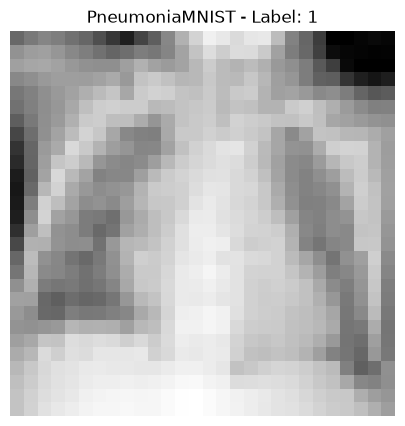

In [5]:
plt.figure(figsize=(5, 5))

plt.imshow(
    image,
    cmap="gray"
)

plt.title(
    f"PneumoniaMNIST - Label: {label}"
)

plt.axis("off")

plt.show()

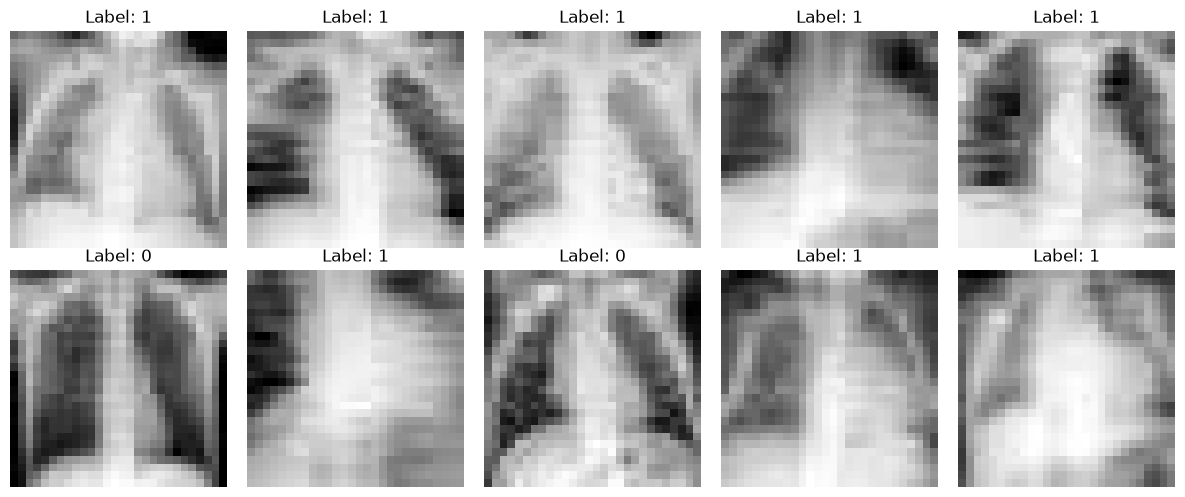

In [6]:
fig, axes = plt.subplots(
    2,
    5,
    figsize=(12, 5)
)

for i, ax in enumerate(axes.flat):

    sample_image, sample_label = (
        train_dataset[i]
    )

    sample_image = np.array(
        sample_image
    )

    sample_label = int(
        sample_label[0]
    )

    ax.imshow(
        sample_image,
        cmap="gray"
    )

    ax.set_title(
        f"Label: {sample_label}"
    )

    ax.axis("off")

plt.tight_layout()
plt.show()

In [7]:
def resize_image(image, size):

    resized = resize(
        image,
        (size, size),
        preserve_range=True,
        anti_aliasing=True
    )

    return np.rint(
        resized
    ).astype(np.uint8)

In [8]:
image_4x4 = resize_image(
    image,
    4
)

print("4×4 image:")
print(image_4x4)

print("\nShape:", image_4x4.shape)
print("Minimum:", image_4x4.min())
print("Maximum:", image_4x4.max())

4×4 image:
[[132 150 160  86]
 [133 160 172 149]
 [127 170 184 143]
 [178 200 192 145]]

Shape: (4, 4)
Minimum: 86
Maximum: 200


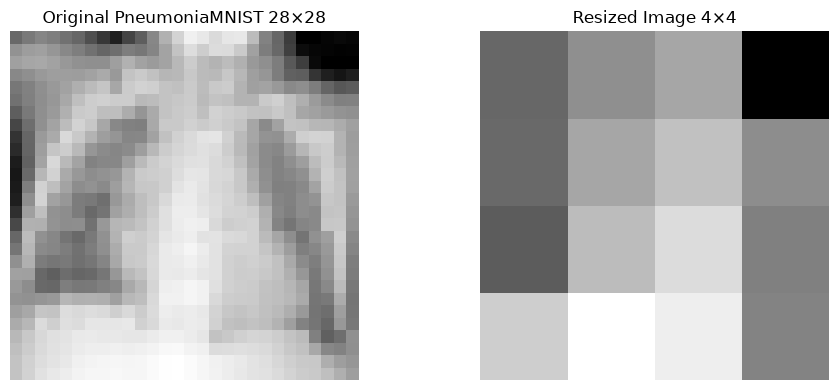

In [9]:
fig, axes = plt.subplots(
    1,
    2,
    figsize=(10, 4)
)

axes[0].imshow(
    image,
    cmap="gray"
)

axes[0].set_title(
    "Original PneumoniaMNIST 28×28"
)

axes[0].axis("off")


axes[1].imshow(
    image_4x4,
    cmap="gray",
    interpolation="nearest"
)

axes[1].set_title(
    "Resized Image 4×4"
)

axes[1].axis("off")

plt.tight_layout()
plt.show()

In [10]:
image_size = 4

num_position_qubits = 4
num_color_qubits = 1

total_qubits = (
    num_position_qubits
    + num_color_qubits
)

print("Image size:", image_size, "×", image_size)
print("Number of position qubits:", num_position_qubits)
print("Number of color qubits:", num_color_qubits)
print("Total qubits:", total_qubits)

Image size: 4 × 4
Number of position qubits: 4
Number of color qubits: 1
Total qubits: 5


In [11]:
position_4 = QuantumRegister(
    4,
    "position"
)

color_4 = QuantumRegister(
    1,
    "color"
)

qc_frqi_4x4 = QuantumCircuit(
    color_4,
    position_4
)

print(
    "Number of qubits:",
    qc_frqi_4x4.num_qubits
)

Number of qubits: 5


In [12]:
#Add Hadamard gates
#which means creating position superposition
qc_frqi_4x4.h(
    position_4
)

qc_frqi_4x4.barrier()

print(
    "Circuit depth:",
    qc_frqi_4x4.depth()
)

Circuit depth: 1


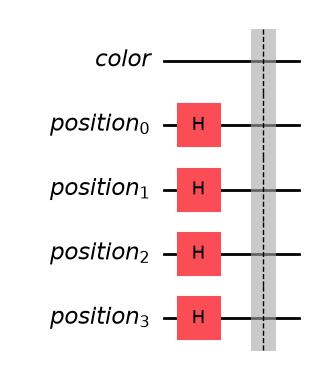

In [13]:
qc_frqi_4x4.draw("mpl")

In [14]:
def intensity_to_theta(pixel_value):

    return (
        pixel_value / 255
    ) * (np.pi / 2)

In [15]:
#Testing the angle conversion
print(
    "Black pixel:",
    np.degrees(
        intensity_to_theta(0)
    ),
    "degrees"
)

print(
    "White pixel:",
    np.degrees(
        intensity_to_theta(255)
    ),
    "degrees"
)

Black pixel: 0.0 degrees
White pixel: 90.0 degrees


In [16]:
#Encode the pixel
def encode_frqi_pixel(
    qc,
    position_qubits,
    color_qubit,
    pixel_position,
    pixel_value
):

    num_position_qubits = len(position_qubits)

    # Binary representation of pixel position
    position_binary = format(
        pixel_position,
        f"0{num_position_qubits}b"
    )

    # FRQI angle
    theta = (
        pixel_value / 255
    ) * (np.pi / 2)

    # Reverse the position bits because
    # Qiskit uses little-endian qubit ordering
    position_binary = position_binary[::-1]

    x_applied = []

    # Convert required 0-controls into 1-controls
    for q, bit in enumerate(position_binary):

        if bit == "0":

            qc.x(
                position_qubits[q]
            )

            x_applied.append(q)

    # Encode intensity
    qc.mcry(
        2 * theta,
        position_qubits,
        color_qubit
    )

    # Restore position qubits
    for q in x_applied:

        qc.x(
            position_qubits[q]
        )

In [17]:
for pixel_position in range(16):

    # Convert pixel index to row and column
    row = pixel_position // 4
    col = pixel_position % 4

    # Get pixel intensity
    pixel_value = int(
        image_4x4[row, col]
    )

    # Encode the pixel
    encode_frqi_pixel(
        qc_frqi_4x4,
        position_4,
        color_4[0],
        pixel_position,
        pixel_value
    )

    qc_frqi_4x4.barrier()

print(
    "FRQI encoding completed."
)

FRQI encoding completed.


In [18]:
print("========== FRQI 4×4 ==========")

print(
    "Qubits:",
    qc_frqi_4x4.num_qubits
)

print(
    "Depth:",
    qc_frqi_4x4.depth()
)

print("\nGate counts:")

print(
    qc_frqi_4x4.count_ops()
)

========== FRQI 4×4 ==========
Qubits: 5
Depth: 717

Gate counts:
OrderedDict({'cx': 384, 't': 256, 'tdg': 192, 'h': 132, 'x': 64, 'ry': 64, 'barrier': 17})




In [19]:
qc_frqi_4x4.draw('mpl')

In [20]:
statevector = Statevector.from_instruction(
    qc_frqi_4x4
)

state = np.asarray(
    statevector
)

print(
    "Number of qubits:",
    qc_frqi_4x4.num_qubits
)

print(
    "Number of amplitudes:",
    len(state)
)

Number of qubits: 5
Number of amplitudes: 32


In [21]:
#checking normalisation
normalization = np.sum(
    np.abs(state) ** 2
)

print(
    "Statevector normalization:",
    normalization
)

Statevector normalization: 0.9999999999999425


In [22]:
#Display non-zero amplitudes
print(
    "Non-zero amplitudes:\n"
)

for i, amplitude in enumerate(state):

    if abs(amplitude) > 1e-10:

        print(
            f"|{i:05b}> : "
            f"{amplitude.real:.8f}"
        )

Non-zero amplitudes:

|00000> : 0.17180917
|00001> : 0.18160839
|00010> : 0.15065866
|00011> : 0.19950431
|00100> : 0.13809124
|00101> : 0.20840060
|00110> : 0.21573225
|00111> : 0.12633130
|01000> : 0.17068721
|01001> : 0.18266328
|01010> : 0.13809124
|01011> : 0.20840060
|01100> : 0.12232323
|01101> : 0.21802988
|01110> : 0.15188474
|01111> : 0.19857247
|10000> : 0.17732033
|10001> : 0.17623139
|10010> : 0.12500000
|10011> : 0.21650635
|10100> : 0.10588713
|10101> : 0.22646836
|10110> : 0.15911856
|10111> : 0.19282449
|11000> : 0.11418316
|11001> : 0.22240100
|11010> : 0.08308870
|11011> : 0.23578861
|11100> : 0.09460276
|11101> : 0.23140941
|11110> : 0.15673095
|11111> : 0.19477014


In [23]:
#printing pixel to angle mapping
print(
    "FRQI pixel encoding:\n"
)

for pixel_position in range(16):

    row = pixel_position // 4
    col = pixel_position % 4

    pixel_value = int(
        image_4x4[row, col]
    )

    theta = intensity_to_theta(
        pixel_value
    )

    print(
        f"Pixel {pixel_position:2d} | "
        f"Row {row} | "
        f"Col {col} | "
        f"Intensity {pixel_value:3d} | "
        f"Theta = "
        f"{np.degrees(theta):.4f}°"
    )

FRQI pixel encoding:

Pixel  0 | Row 0 | Col 0 | Intensity 132 | Theta = 46.5882°
Pixel  1 | Row 0 | Col 1 | Intensity 150 | Theta = 52.9412°
Pixel  2 | Row 0 | Col 2 | Intensity 160 | Theta = 56.4706°
Pixel  3 | Row 0 | Col 3 | Intensity  86 | Theta = 30.3529°
Pixel  4 | Row 1 | Col 0 | Intensity 133 | Theta = 46.9412°
Pixel  5 | Row 1 | Col 1 | Intensity 160 | Theta = 56.4706°
Pixel  6 | Row 1 | Col 2 | Intensity 172 | Theta = 60.7059°
Pixel  7 | Row 1 | Col 3 | Intensity 149 | Theta = 52.5882°
Pixel  8 | Row 2 | Col 0 | Intensity 127 | Theta = 44.8235°
Pixel  9 | Row 2 | Col 1 | Intensity 170 | Theta = 60.0000°
Pixel 10 | Row 2 | Col 2 | Intensity 184 | Theta = 64.9412°
Pixel 11 | Row 2 | Col 3 | Intensity 143 | Theta = 50.4706°
Pixel 12 | Row 3 | Col 0 | Intensity 178 | Theta = 62.8235°
Pixel 13 | Row 3 | Col 1 | Intensity 200 | Theta = 70.5882°
Pixel 14 | Row 3 | Col 2 | Intensity 192 | Theta = 67.7647°
Pixel 15 | Row 3 | Col 3 | Intensity 145 | Theta = 51.1765°


In [24]:
#Decode 
def decode_frqi_statevector(
    statevector,
    image_size
):

    state = np.asarray(
        statevector
    )

    reconstructed = np.zeros(
        (image_size, image_size),
        dtype=np.uint8
    )

    num_position_qubits = (
        2 * int(np.log2(image_size))
    )

    for pixel_position in range(
        image_size * image_size
    ):

        # Position occupies the higher qubits.
        # Color is the lowest qubit.
        index_color_0 = (
            pixel_position << 1
        )

        index_color_1 = (
            (pixel_position << 1)
            | 1
        )

        amplitude_0 = abs(
            state[index_color_0]
        )

        amplitude_1 = abs(
            state[index_color_1]
        )

        # Recover theta
        theta = np.arctan2(
            amplitude_1,
            amplitude_0
        )

        # Convert theta back to intensity
        pixel_value = (
            theta / (np.pi / 2)
        ) * 255

        pixel_value = np.clip(
            np.rint(pixel_value),
            0,
            255
        )

        row = (
            pixel_position // image_size
        )

        col = (
            pixel_position % image_size
        )

        reconstructed[
            row,
            col
        ] = int(pixel_value)

    return reconstructed

In [25]:
#reconstruct
reconstructed_4x4 = (
    decode_frqi_statevector(
        statevector,
        4
    )
)

print("Original 4×4:")
print(image_4x4)

print("\nReconstructed 4×4:")
print(reconstructed_4x4)

Original 4×4:
[[132 150 160  86]
 [133 160 172 149]
 [127 170 184 143]
 [178 200 192 145]]

Reconstructed 4×4:
[[132 150 160  86]
 [133 160 172 149]
 [127 170 184 143]
 [178 200 192 145]]


In [26]:
difference_4x4 = np.abs(
    image_4x4.astype(int)
    -
    reconstructed_4x4.astype(int)
)

print(
    "Difference matrix:"
)

print(difference_4x4)

Difference matrix:
[[0 0 0 0]
 [0 0 0 0]
 [0 0 0 0]
 [0 0 0 0]]


In [27]:
mse_4x4 = np.mean(
    (
        image_4x4.astype(np.float64)
        -
        reconstructed_4x4.astype(np.float64)
    ) ** 2
)

print(
    "MSE:",
    mse_4x4
)

MSE: 0.0


In [28]:
if mse_4x4 == 0:

    psnr_4x4 = float("inf")

else:

    psnr_4x4 = (
        10
        * np.log10(
            (255 ** 2)
            / mse_4x4
        )
    )

print(
    "PSNR:",
    psnr_4x4,
    "dB"
)

PSNR: inf dB


In [29]:
max_error_4x4 = np.max(
    np.abs(
        image_4x4.astype(int)
        -
        reconstructed_4x4.astype(int)
    )
)

print(
    "Maximum pixel error:",
    max_error_4x4
)

Maximum pixel error: 0


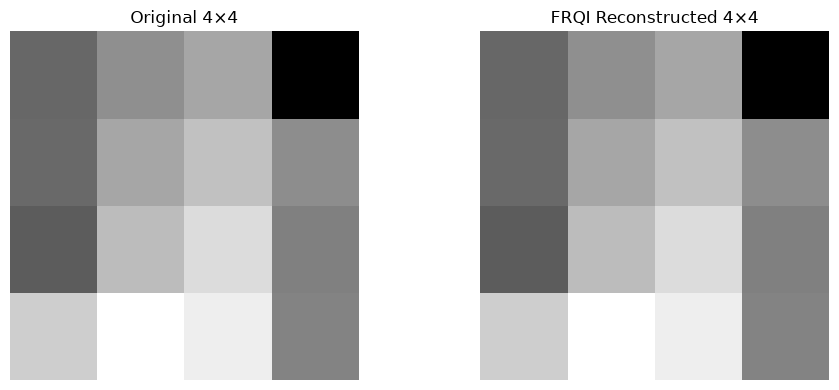

In [30]:
fig, axes = plt.subplots(
    1,
    2,
    figsize=(10, 4)
)

axes[0].imshow(
    image_4x4,
    cmap="gray",
    interpolation="nearest"
)

axes[0].set_title(
    "Original 4×4"
)

axes[0].axis("off")


axes[1].imshow(
    reconstructed_4x4,
    cmap="gray",
    interpolation="nearest"
)

axes[1].set_title(
    "FRQI Reconstructed 4×4"
)

axes[1].axis("off")

plt.tight_layout()
plt.show()

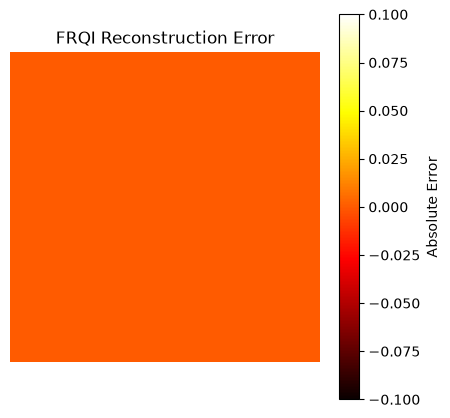

In [31]:
plt.figure(figsize=(5, 5))

plt.imshow(
    difference_4x4,
    cmap="hot",
    interpolation="nearest"
)

plt.title(
    "FRQI Reconstruction Error"
)

plt.colorbar(
    label="Absolute Error"
)

plt.axis("off")

plt.show()

In [32]:
classical_4 = ClassicalRegister(
    5,
    "cr"
)

In [33]:
qc_frqi_4x4_measure = (
    qc_frqi_4x4.copy()
)

qc_frqi_4x4_measure.add_register(
    classical_4
)

qc_frqi_4x4_measure.measure(
    range(5),
    range(5)
)

print(
    "Measurement circuit created."
)

Measurement circuit created.


In [34]:
simulator = AerSimulator()

transpiled_frqi_4x4 = transpile(
    qc_frqi_4x4_measure,
    simulator
)

job = simulator.run(
    transpiled_frqi_4x4,
    shots=4096
)

result = job.result()

counts_frqi_4x4 = (
    result.get_counts()
)

print(
    "Number of measured states:",
    len(counts_frqi_4x4)
)

print(
    "\nMeasurement counts:"
)

print(counts_frqi_4x4)

Number of measured states: 32

Measurement counts:
{'11101': 213, '10011': 210, '11110': 102, '00100': 104, '10101': 204, '01111': 159, '00011': 161, '10001': 124, '11011': 258, '00101': 184, '10010': 76, '11010': 34, '10100': 43, '10111': 151, '10000': 109, '11111': 168, '00001': 136, '01101': 188, '00000': 112, '01001': 126, '11001': 166, '00110': 194, '00111': 71, '01110': 92, '01000': 150, '00010': 100, '10110': 97, '01011': 142, '01100': 68, '11100': 28, '01010': 79, '11000': 47}


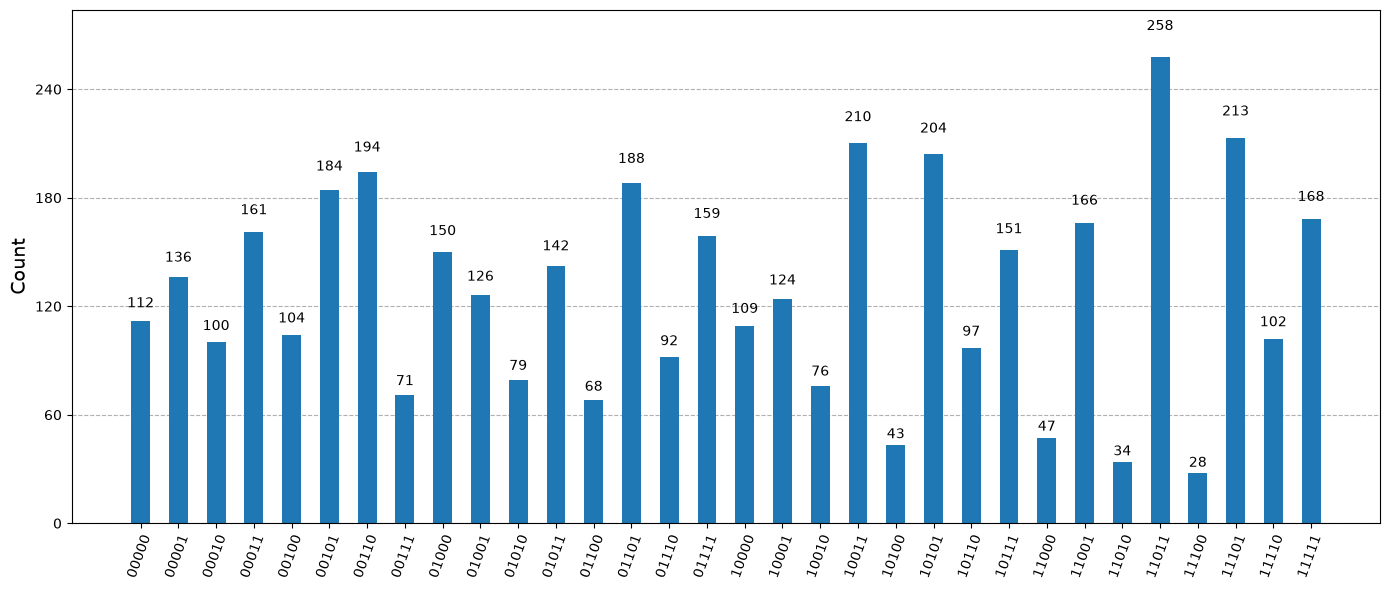

In [35]:
plot_histogram(
    counts_frqi_4x4,
    figsize=(14, 6)
)

In [36]:
print("========== FRQI 4×4 RESULTS ==========")

print(
    "Resolution:",
    "4×4"
)

print(
    "Pixels:",
    16
)

print(
    "Total qubits:",
    qc_frqi_4x4.num_qubits
)

print(
    "Original circuit depth:",
    qc_frqi_4x4.depth()
)

print(
    "Transpiled circuit depth:",
    transpiled_frqi_4x4.depth()
)

print(
    "\nOriginal gate counts:"
)

print(
    qc_frqi_4x4.count_ops()
)

print(
    "\nTranspiled gate counts:"
)

print(
    transpiled_frqi_4x4.count_ops()
)

print(
    "\nReconstruction MSE:",
    mse_4x4
)

print(
    "Reconstruction PSNR:",
    psnr_4x4,
    "dB"
)

print(
    "Maximum pixel error:",
    max_error_4x4
)

========== FRQI 4×4 RESULTS ==========
Resolution: 4×4
Pixels: 16
Total qubits: 5
Original circuit depth: 717
Transpiled circuit depth: 544

Original gate counts:
OrderedDict({'cx': 384, 't': 256, 'tdg': 192, 'h': 132, 'x': 64, 'ry': 64, 'barrier': 17})

Transpiled gate counts:
OrderedDict({'cx': 224, 't': 116, 'u3': 103, 'tdg': 99, 'u1': 54, 'rzz': 49, 'cp': 39, 'u2': 35, 'x': 32, 'barrier': 17, 'h': 12, 'measure': 5, 'cry': 3, 'rzx': 3, 'crz': 2})

Reconstruction MSE: 0.0
Reconstruction PSNR: inf dB
Maximum pixel error: 0


In [37]:
print(image_4x4)
print(reconstructed_4x4)

[[132 150 160  86]
 [133 160 172 149]
 [127 170 184 143]
 [178 200 192 145]]
[[132 150 160  86]
 [133 160 172 149]
 [127 170 184 143]
 [178 200 192 145]]


In [38]:
print(difference_4x4)

[[0 0 0 0]
 [0 0 0 0]
 [0 0 0 0]
 [0 0 0 0]]


8x8 Image:
[[131 118 112 148 181 149  62  11]
 [119 156 163 168 173 159 138 101]
 [107 161 133 167 189 154 151 159]
 [118 136 141 184 196 158 127 162]
 [130 115 150 193 200 175 126 153]
 [124 108 145 197 202 180 145 138]
 [157 179 183 201 197 175 147 118]
 [185 207 213 217 209 196 175 137]]


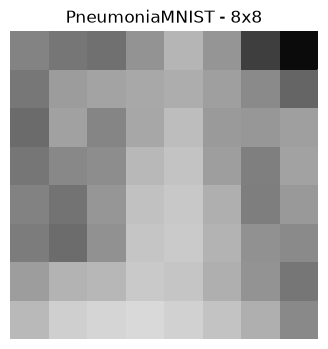

In [39]:
# Resize the SAME original image to 8x8
image_8x8 = resize_image(image, 8)

print("8x8 Image:")
print(image_8x8)

plt.figure(figsize=(4,4))
plt.imshow(image_8x8, cmap='gray', vmin=0, vmax=255)
plt.title("PneumoniaMNIST - 8x8")
plt.axis("off")
plt.show()

In [40]:
#Create 8x8 FRQI circuit
num_position_qubits_8 = 6

color_8 = QuantumRegister(1, "color")
position_8 = QuantumRegister(
    num_position_qubits_8,
    "position"
)

qc_frqi_8x8 = QuantumCircuit(
    color_8,
    position_8
)

# Uniform superposition of all 64 positions
qc_frqi_8x8.h(position_8)

qc_frqi_8x8.barrier()

print("Total qubits:", qc_frqi_8x8.num_qubits)

Total qubits: 7


In [41]:
#Encode all 64 pixels
flat_8x8 = image_8x8.flatten()

for pixel_position, pixel_value in enumerate(flat_8x8):

    encode_frqi_pixel(
        qc_frqi_8x8,
        position_8,
        color_8[0],
        pixel_position,
        int(pixel_value)
    )

qc_frqi_8x8.barrier()

print("Encoding completed")
print("Pixels encoded:", len(flat_8x8))
print("Circuit depth:", qc_frqi_8x8.depth())
print("Gate counts:")
print(qc_frqi_8x8.count_ops())

Encoding completed
Pixels encoded: 64
Circuit depth: 4875
Gate counts:
OrderedDict({'p': 3840, 'cx': 3584, 'h': 518, 'x': 384, 'ry': 256, 'barrier': 2})


In [42]:
#Statevector simulation
qc_sv_8 = qc_frqi_8x8.copy()
qc_sv_8.save_statevector()

simulator_sv = AerSimulator(method="statevector")

t_qc_sv_8 = transpile(
    qc_sv_8,
    simulator_sv
)

result_sv_8 = simulator_sv.run(
    t_qc_sv_8
).result()

statevector_8 = np.asarray(
    result_sv_8.get_statevector()
)

print("Statevector length:", len(statevector_8))

norm_8 = np.sum(
    np.abs(statevector_8)**2
)

print("Normalization:", norm_8)

Statevector length: 128
Normalization: 1.0000000000000022


In [43]:
#Decode 
reconstructed_8 = []

num_pixels_8 = 64

for p in range(num_pixels_8):

    index_color_0 = 2 * p
    index_color_1 = 2 * p + 1

    amp0 = statevector_8[index_color_0]
    amp1 = statevector_8[index_color_1]

    # Remove position normalization factor
    amp0 = amp0 * np.sqrt(num_pixels_8)
    amp1 = amp1 * np.sqrt(num_pixels_8)

    theta = np.arctan2(
        np.abs(amp1),
        np.abs(amp0)
    )

    pixel_value = (
        theta / (np.pi / 2)
    ) * 255

    reconstructed_8.append(
        int(round(pixel_value))
    )

reconstructed_8 = np.array(
    reconstructed_8
).reshape(8,8)

print("Original 8x8:")
print(image_8x8)

print("\nReconstructed 8x8:")
print(reconstructed_8)

Original 8x8:
[[131 118 112 148 181 149  62  11]
 [119 156 163 168 173 159 138 101]
 [107 161 133 167 189 154 151 159]
 [118 136 141 184 196 158 127 162]
 [130 115 150 193 200 175 126 153]
 [124 108 145 197 202 180 145 138]
 [157 179 183 201 197 175 147 118]
 [185 207 213 217 209 196 175 137]]

Reconstructed 8x8:
[[131 118 112 148 181 149  62  11]
 [119 156 163 168 173 159 138 101]
 [107 161 133 167 189 154 151 159]
 [118 136 141 184 196 158 127 162]
 [130 115 150 193 200 175 126 153]
 [124 108 145 197 202 180 145 138]
 [157 179 183 201 197 175 147 118]
 [185 207 213 217 209 196 175 137]]


In [44]:
#Difference in original to reconstruct
difference_8 = (
    image_8x8.astype(int)
    - reconstructed_8.astype(int)
)

print("Difference matrix:")
print(difference_8)

print(
    "\nMaximum absolute error:",
    np.max(np.abs(difference_8))
)

Difference matrix:
[[0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0]]

Maximum absolute error: 0


In [45]:
#MSE and PSNR
mse_8 = np.mean(
    (
        image_8x8.astype(float)
        - reconstructed_8.astype(float)
    ) ** 2
)

if mse_8 == 0:
    psnr_8 = float("inf")
else:
    psnr_8 = 10 * np.log10(
        (255 ** 2) / mse_8
    )

print("MSE :", mse_8)
print("PSNR:", psnr_8)

MSE : 0.0
PSNR: inf


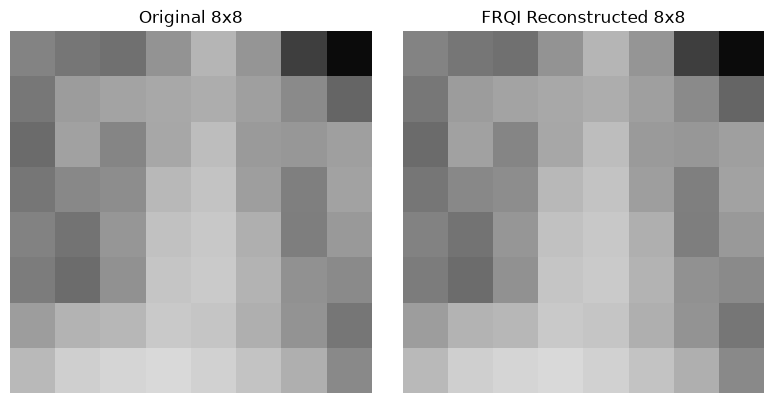

In [46]:
plt.figure(figsize=(8,4))

plt.subplot(1,2,1)
plt.imshow(
    image_8x8,
    cmap="gray",
    vmin=0,
    vmax=255
)
plt.title("Original 8x8")
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(
    reconstructed_8,
    cmap="gray",
    vmin=0,
    vmax=255
)
plt.title("FRQI Reconstructed 8x8")
plt.axis("off")

plt.tight_layout()
plt.show()

Number of measured states: 127


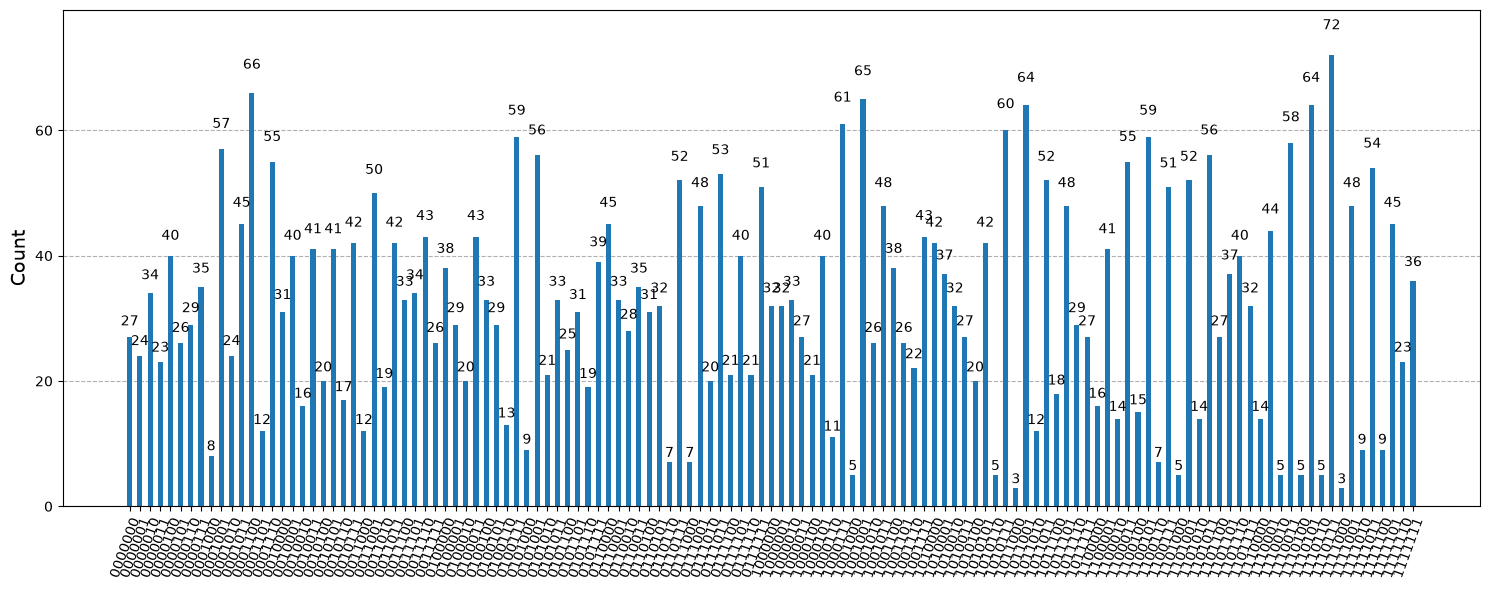

In [47]:
#Measurement and Histogram
qc_measure_8 = qc_frqi_8x8.copy()

cr_8 = ClassicalRegister(
    qc_measure_8.num_qubits,
    "cr"
)

qc_measure_8.add_register(cr_8)

qc_measure_8.measure(
    range(qc_measure_8.num_qubits),
    range(qc_measure_8.num_qubits)
)

simulator = AerSimulator()

t_qc_measure_8 = transpile(
    qc_measure_8,
    simulator
)

result_measure_8 = simulator.run(
    t_qc_measure_8,
    shots=4096
).result()

counts_8 = result_measure_8.get_counts()

print("Number of measured states:", len(counts_8))

plot_histogram(
    counts_8,
    figsize=(15,6)
)

In [48]:
print("===== FRQI 8x8 SUMMARY =====")

print("Resolution       : 8x8")
print("Pixels           :", 64)
print("Position qubits  :", 6)
print("Color qubits     :", 1)
print("Total qubits     :", 7)
print("Circuit depth    :", qc_frqi_8x8.depth())
print("Gate counts      :", qc_frqi_8x8.count_ops())
print("MSE              :", mse_8)
print("PSNR             :", psnr_8)
print(
    "Maximum error    :",
    np.max(np.abs(difference_8))
)

===== FRQI 8x8 SUMMARY =====
Resolution       : 8x8
Pixels           : 64
Position qubits  : 6
Color qubits     : 1
Total qubits     : 7
Circuit depth    : 4875
Gate counts      : OrderedDict({'p': 3840, 'cx': 3584, 'h': 518, 'x': 384, 'ry': 256, 'barrier': 2})
MSE              : 0.0
PSNR             : inf
Maximum error    : 0


In [49]:
from qiskit import transpile
from qiskit_aer import AerSimulator

backend_8 = AerSimulator()

transpiled_8 = transpile(
    qc_frqi_8x8,
    backend_8
)

print("Original depth:",
      qc_frqi_8x8.depth())

print("Transpiled depth:",
      transpiled_8.depth())

print("\nOriginal gates:")
print(qc_frqi_8x8.count_ops())

print("\nTranspiled gates:")
print(transpiled_8.count_ops())

Original depth: 4875
Transpiled depth: 4106

Original gates:
OrderedDict({'p': 3840, 'cx': 3584, 'h': 518, 'x': 384, 'ry': 256, 'barrier': 2})

Transpiled gates:
OrderedDict({'cx': 2914, 'p': 2872, 'u3': 391, 'rzz': 267, 'u2': 155, 'cp': 103, 'u1': 22, 'crz': 14, 'rzx': 12, 'crx': 7, 'h': 6, 'cry': 4, 'ryy': 4, 'rxx': 3, 'barrier': 2})


In [50]:
depth_overhead_8 = (
    (transpiled_8.depth() - qc_frqi_8x8.depth())
    / qc_frqi_8x8.depth()
) * 100

cx_original_8 = qc_frqi_8x8.count_ops().get("cx", 0)
cx_transpiled_8 = transpiled_8.count_ops().get("cx", 0)

cx_overhead_8 = (
    (cx_transpiled_8 - cx_original_8)
    / cx_original_8
) * 100

print("Depth change (%):", depth_overhead_8)
print("CX change (%):", cx_overhead_8)

Depth change (%): -15.774358974358973
CX change (%): -18.694196428571427


16x16 Image:
[[112 125 110  88  62  82 115 170 200 193 193 130  77   6   4   5]
 [140 145 135 128 133 155 142 156 174 162 158 130  98  52   6   4]
 [111 128 142 158 161 178 180 169 173 175 161 142 127 117  84  72]
 [ 98 127 150 178 172 160 155 175 175 179 171 170 174 148 132 123]
 [ 72 132 171 173 137 116 143 178 187 189 170 134 148 173 169 145]
 [ 57 144 178 142 121 128 161 185 195 192 166 131 125 159 179 148]
 [ 51 161 156 128 129 158 180 190 202 191 176 134 117 133 178 153]
 [ 64 178 139 115 119 156 175 198 204 191 180 146 115 125 171 152]
 [ 89 158 125 104 127 159 180 204 208 193 184 165 116 121 166 149]
 [121 127 106 104 139 180 186 205 207 199 189 173 139 108 139 145]
 [136 111 107 103 130 176 189 207 209 197 182 180 160 121 130 137]
 [134  94 104 103 116 156 186 209 211 196 181 175 164 136 122 131]
 [135 147 169 169 164 173 189 210 211 188 177 172 163 138 105 121]
 [157 190 195 200 203 201 193 206 207 181 170 171 156 121  93 117]
 [172 192 201 208 210 209 213 218 212 192 194 192

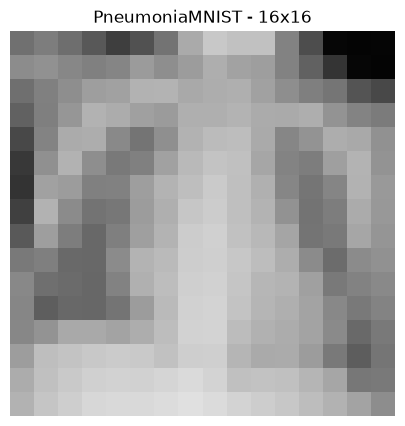

In [51]:
image_16x16 = resize_image(image, 16)

print("16x16 Image:")
print(image_16x16)

plt.figure(figsize=(5, 5))
plt.imshow(image_16x16, cmap="gray", vmin=0, vmax=255)
plt.title("PneumoniaMNIST - 16x16")
plt.axis("off")
plt.show()

In [52]:
#Create 16x16 circuit
num_position_qubits_16 = 8

color_16 = QuantumRegister(1, "color")
position_16 = QuantumRegister(
    num_position_qubits_16,
    "position"
)

qc_frqi_16x16 = QuantumCircuit(
    color_16,
    position_16
)

# Put all 256 positions into superposition
qc_frqi_16x16.h(position_16)

qc_frqi_16x16.barrier()

print("Total qubits:", qc_frqi_16x16.num_qubits)

Total qubits: 9


In [53]:
#Encode all 256 pixels
flat_16x16 = image_16x16.flatten()

for pixel_position, pixel_value in enumerate(flat_16x16):

    encode_frqi_pixel(
        qc_frqi_16x16,
        position_16,
        color_16[0],
        pixel_position,
        int(pixel_value)
    )

qc_frqi_16x16.barrier()

print("Encoding completed")
print("Pixels encoded:", len(flat_16x16))

print("\nOriginal circuit depth:")
print(qc_frqi_16x16.depth())

print("\nOriginal gate counts:")
print(qc_frqi_16x16.count_ops())

Encoding completed
Pixels encoded: 256

Original circuit depth:
50435

Original gate counts:
OrderedDict({'cx': 26624, 't': 16384, 'tdg': 14336, 'h': 12296, 'x': 2048, 'ry': 1024, 'barrier': 2})


In [54]:
#Statevector simulation
qc_sv_16 = qc_frqi_16x16.copy()
qc_sv_16.save_statevector()

simulator_sv_16 = AerSimulator(
    method="statevector"
)

t_qc_sv_16 = transpile(
    qc_sv_16,
    simulator_sv_16
)

result_sv_16 = simulator_sv_16.run(
    t_qc_sv_16
).result()

statevector_16 = np.asarray(
    result_sv_16.get_statevector()
)

print("Statevector length:", len(statevector_16))

norm_16 = np.sum(
    np.abs(statevector_16) ** 2
)

print("Normalization:", norm_16)

Statevector length: 512
Normalization: 1.000000000000338


In [55]:
#Reconstruct 16x16 image
reconstructed_16 = []

num_pixels_16 = 256

for p in range(num_pixels_16):

    index_color_0 = 2 * p
    index_color_1 = 2 * p + 1

    amp0 = statevector_16[index_color_0]
    amp1 = statevector_16[index_color_1]

    # Remove position normalization
    amp0 = amp0 * np.sqrt(num_pixels_16)
    amp1 = amp1 * np.sqrt(num_pixels_16)

    theta = np.arctan2(
        np.abs(amp1),
        np.abs(amp0)
    )

    pixel_value = (
        theta / (np.pi / 2)
    ) * 255

    reconstructed_16.append(
        int(round(pixel_value))
    )

reconstructed_16 = np.array(
    reconstructed_16
).reshape(16, 16)

print("Original 16x16:")
print(image_16x16)

print("\nReconstructed 16x16:")
print(reconstructed_16)

Original 16x16:
[[112 125 110  88  62  82 115 170 200 193 193 130  77   6   4   5]
 [140 145 135 128 133 155 142 156 174 162 158 130  98  52   6   4]
 [111 128 142 158 161 178 180 169 173 175 161 142 127 117  84  72]
 [ 98 127 150 178 172 160 155 175 175 179 171 170 174 148 132 123]
 [ 72 132 171 173 137 116 143 178 187 189 170 134 148 173 169 145]
 [ 57 144 178 142 121 128 161 185 195 192 166 131 125 159 179 148]
 [ 51 161 156 128 129 158 180 190 202 191 176 134 117 133 178 153]
 [ 64 178 139 115 119 156 175 198 204 191 180 146 115 125 171 152]
 [ 89 158 125 104 127 159 180 204 208 193 184 165 116 121 166 149]
 [121 127 106 104 139 180 186 205 207 199 189 173 139 108 139 145]
 [136 111 107 103 130 176 189 207 209 197 182 180 160 121 130 137]
 [134  94 104 103 116 156 186 209 211 196 181 175 164 136 122 131]
 [135 147 169 169 164 173 189 210 211 188 177 172 163 138 105 121]
 [157 190 195 200 203 201 193 206 207 181 170 171 156 121  93 117]
 [172 192 201 208 210 209 213 218 212 192 194 

In [56]:
#Difference matrix
difference_16 = (
    image_16x16.astype(int)
    - reconstructed_16.astype(int)
)

print("Difference matrix:")
print(difference_16)

print(
    "\nMaximum absolute error:",
    np.max(np.abs(difference_16))
)

Difference matrix:
[[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]]

Maximum absolute error: 0


In [57]:
#MSE and PSNR
mse_16 = np.mean(
    (
        image_16x16.astype(float)
        - reconstructed_16.astype(float)
    ) ** 2
)

if mse_16 == 0:
    psnr_16 = float("inf")
else:
    psnr_16 = 10 * np.log10(
        (255 ** 2) / mse_16
    )

print("MSE :", mse_16)
print("PSNR:", psnr_16)

MSE : 0.0
PSNR: inf


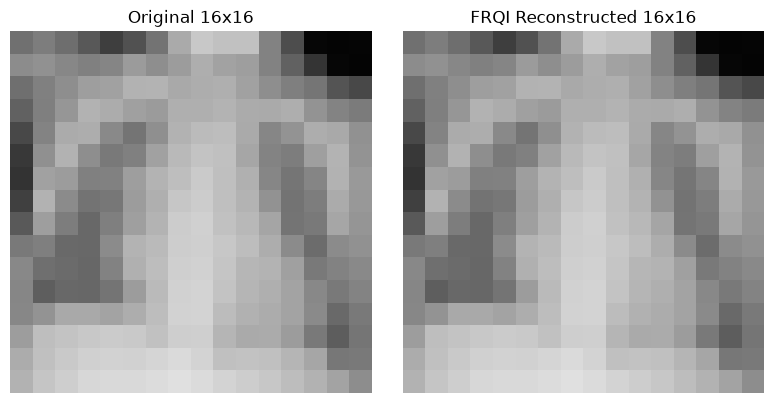

In [58]:
plt.figure(figsize=(8, 4))

plt.subplot(1, 2, 1)
plt.imshow(
    image_16x16,
    cmap="gray",
    vmin=0,
    vmax=255
)
plt.title("Original 16x16")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(
    reconstructed_16,
    cmap="gray",
    vmin=0,
    vmax=255
)
plt.title("FRQI Reconstructed 16x16")
plt.axis("off")

plt.tight_layout()
plt.show()

In [59]:
#Transpilation
backend_16 = AerSimulator()

transpiled_16 = transpile(
    qc_frqi_16x16,
    backend_16
)

print("Original depth:",
      qc_frqi_16x16.depth())

print("Transpiled depth:",
      transpiled_16.depth())

print("\nOriginal gates:")
print(qc_frqi_16x16.count_ops())

print("\nTranspiled gates:")
print(transpiled_16.count_ops())

Original depth: 50435
Transpiled depth: 39961

Original gates:
OrderedDict({'cx': 26624, 't': 16384, 'tdg': 14336, 'h': 12296, 'x': 2048, 'ry': 1024, 'barrier': 2})

Transpiled gates:
OrderedDict({'cx': 21922, 't': 8704, 'u2': 8454, 'tdg': 7769, 'u1': 2075, 'rzz': 2047, 'u3': 1361, 'cp': 424, 'x': 343, 'rzx': 183, 'h': 9, 'barrier': 2})


In [60]:
#Depth and CX Change
original_depth_16 = qc_frqi_16x16.depth()
transpiled_depth_16 = transpiled_16.depth()

original_cx_16 = qc_frqi_16x16.count_ops().get("cx", 0)
transpiled_cx_16 = transpiled_16.count_ops().get("cx", 0)

depth_change_16 = (
    (transpiled_depth_16 - original_depth_16)
    / original_depth_16
) * 100

cx_change_16 = (
    (transpiled_cx_16 - original_cx_16)
    / original_cx_16
) * 100

print("Depth change (%):", depth_change_16)
print("CX change (%):", cx_change_16)

Depth change (%): -20.76732427877466
CX change (%): -17.66075721153846


In [61]:
print("===== FRQI 16x16 SUMMARY =====")

print("Resolution       : 16x16")
print("Pixels           :", 256)
print("Position qubits  :", 8)
print("Color qubits     :", 1)
print("Total qubits     :", 9)

print("Original depth   :", original_depth_16)
print("Transpiled depth :", transpiled_depth_16)

print("Original CX      :", original_cx_16)
print("Transpiled CX    :", transpiled_cx_16)

print("MSE              :", mse_16)
print("PSNR             :", psnr_16)
print(
    "Maximum error    :",
    np.max(np.abs(difference_16))
)

===== FRQI 16x16 SUMMARY =====
Resolution       : 16x16
Pixels           : 256
Position qubits  : 8
Color qubits     : 1
Total qubits     : 9
Original depth   : 50435
Transpiled depth : 39961
Original CX      : 26624
Transpiled CX    : 21922
MSE              : 0.0
PSNR             : inf
Maximum error    : 0


In [62]:
#BloodMNIST dataset
from medmnist import BloodMNIST

blood_train = BloodMNIST(
    split="train",
    download=True
)

blood_test = BloodMNIST(
    split="test",
    download=True
)

print("Training samples:", len(blood_train))
print("Testing samples :", len(blood_test))

Training samples: 11959
Testing samples : 3421


Image type : <class 'PIL.Image.Image'>
Image size : (28, 28)
Label      : [7]


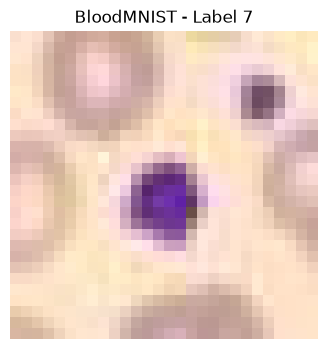

In [63]:
blood_image, blood_label = blood_train[0]

print("Image type :", type(blood_image))
print("Image size :", blood_image.size)
print("Label      :", blood_label)

plt.figure(figsize=(4,4))
plt.imshow(blood_image)
plt.title(f"BloodMNIST - Label {blood_label[0]}")
plt.axis("off")
plt.show()

In [64]:
#Convert RGB image to grayscale
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

blood_rgb, blood_label = blood_train[0]

blood_gray = blood_rgb.convert("L")

print("Original RGB size :", blood_rgb.size)
print("Grayscale size    :", blood_gray.size)
print("Grayscale mode    :", blood_gray.mode)

Original RGB size : (28, 28)
Grayscale size    : (28, 28)
Grayscale mode    : L


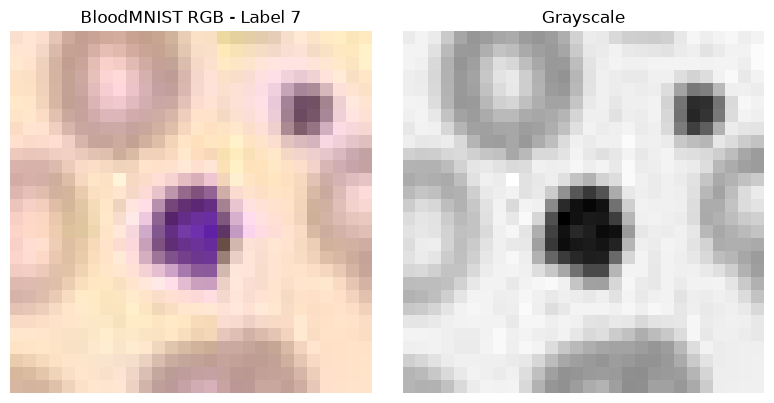

In [65]:
plt.figure(figsize=(8, 4))

plt.subplot(1, 2, 1)
plt.imshow(blood_rgb)
plt.title(f"BloodMNIST RGB - Label {blood_label[0]}")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(blood_gray, cmap="gray")
plt.title("Grayscale")
plt.axis("off")

plt.tight_layout()
plt.show()

In [66]:
original_blood_image = np.array(
    blood_gray,
    dtype=np.uint8
)

print("Shape:", original_blood_image.shape)
print("Minimum intensity:", original_blood_image.min())
print("Maximum intensity:", original_blood_image.max())

Shape: (28, 28)
Minimum intensity: 59
Maximum intensity: 244


In [67]:
blood_4x4 = resize_image(
    original_blood_image,
    4
)

print("BloodMNIST 4x4:")
print(blood_4x4)

BloodMNIST 4x4:
[[203 195 220 212]
 [207 200 209 202]
 [215 192 189 212]
 [223 216 195 220]]


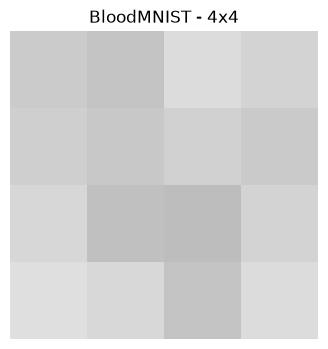

In [68]:
plt.figure(figsize=(4, 4))

plt.imshow(
    blood_4x4,
    cmap="gray",
    vmin=0,
    vmax=255
)

plt.title("BloodMNIST - 4x4")
plt.axis("off")
plt.show()

In [69]:
num_position_qubits_blood_4 = 4

color_blood_4 = QuantumRegister(
    1,
    "color"
)

position_blood_4 = QuantumRegister(
    num_position_qubits_blood_4,
    "position"
)

qc_blood_frqi_4x4 = QuantumCircuit(
    color_blood_4,
    position_blood_4
)

# Put all 16 positions into superposition
qc_blood_frqi_4x4.h(
    position_blood_4
)

qc_blood_frqi_4x4.barrier()

print(
    "Total qubits:",
    qc_blood_frqi_4x4.num_qubits
)

Total qubits: 5


In [70]:
#Encode
flat_blood_4 = blood_4x4.flatten()

for pixel_position, pixel_value in enumerate(
    flat_blood_4
):

    encode_frqi_pixel(
        qc_blood_frqi_4x4,
        position_blood_4,
        color_blood_4[0],
        pixel_position,
        int(pixel_value)
    )

qc_blood_frqi_4x4.barrier()

print("Pixels encoded:", len(flat_blood_4))

print(
    "Original depth:",
    qc_blood_frqi_4x4.depth()
)

print(
    "Gate counts:",
    qc_blood_frqi_4x4.count_ops()
)

Pixels encoded: 16
Original depth: 705
Gate counts: OrderedDict({'cx': 384, 't': 256, 'tdg': 192, 'h': 132, 'x': 64, 'ry': 64, 'barrier': 2})


In [71]:
#Statevector simulation
qc_blood_sv_4 = qc_blood_frqi_4x4.copy()

qc_blood_sv_4.save_statevector()

simulator_blood = AerSimulator(
    method="statevector"
)

t_qc_blood_sv_4 = transpile(
    qc_blood_sv_4,
    simulator_blood
)

result_blood_sv_4 = simulator_blood.run(
    t_qc_blood_sv_4
).result()

statevector_blood_4 = np.asarray(
    result_blood_sv_4.get_statevector()
)

print(
    "Statevector length:",
    len(statevector_blood_4)
)

print(
    "Normalization:",
    np.sum(
        np.abs(statevector_blood_4) ** 2
    )
)

Statevector length: 32
Normalization: 0.9999999999999962


In [72]:
#Reconstruct MNIST
reconstructed_blood_4 = []

num_pixels_blood_4 = 16

for p in range(num_pixels_blood_4):

    index_color_0 = 2 * p
    index_color_1 = 2 * p + 1

    amp0 = statevector_blood_4[
        index_color_0
    ]

    amp1 = statevector_blood_4[
        index_color_1
    ]

    # Remove position normalization
    amp0 *= np.sqrt(num_pixels_blood_4)
    amp1 *= np.sqrt(num_pixels_blood_4)

    theta = np.arctan2(
        np.abs(amp1),
        np.abs(amp0)
    )

    pixel_value = (
        theta / (np.pi / 2)
    ) * 255

    reconstructed_blood_4.append(
        int(round(pixel_value))
    )

reconstructed_blood_4 = np.array(
    reconstructed_blood_4
).reshape(4, 4)

print("Original:")
print(blood_4x4)

print("\nReconstructed:")
print(reconstructed_blood_4)

Original:
[[203 195 220 212]
 [207 200 209 202]
 [215 192 189 212]
 [223 216 195 220]]

Reconstructed:
[[203 195 220 212]
 [207 200 209 202]
 [215 192 189 212]
 [223 216 195 220]]


In [73]:
#Difference check
difference_blood_4 = (
    blood_4x4.astype(int)
    - reconstructed_blood_4.astype(int)
)

print("Difference:")
print(difference_blood_4)

print(
    "\nMaximum absolute error:",
    np.max(
        np.abs(difference_blood_4)
    )
)

Difference:
[[0 0 0 0]
 [0 0 0 0]
 [0 0 0 0]
 [0 0 0 0]]

Maximum absolute error: 0


In [74]:
#MSE+PSNR
mse_blood_4 = np.mean(
    (
        blood_4x4.astype(float)
        - reconstructed_blood_4.astype(float)
    ) ** 2
)

if mse_blood_4 == 0:
    psnr_blood_4 = float("inf")
else:
    psnr_blood_4 = 10 * np.log10(
        (255 ** 2) / mse_blood_4
    )

print("MSE :", mse_blood_4)
print("PSNR:", psnr_blood_4)

MSE : 0.0
PSNR: inf


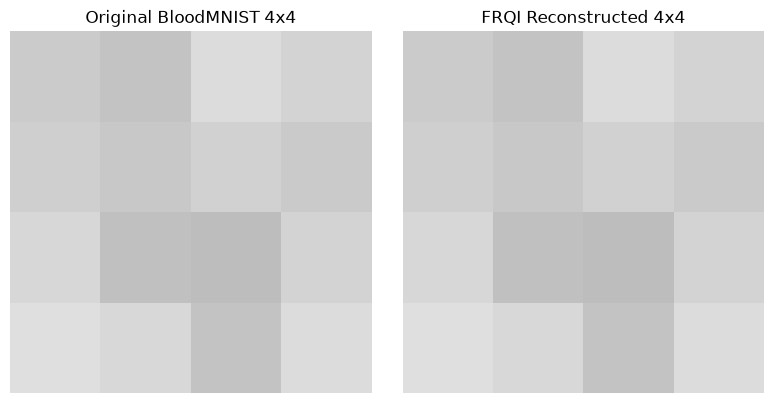

In [75]:
#original vs reconstructed
plt.figure(figsize=(8, 4))

plt.subplot(1, 2, 1)

plt.imshow(
    blood_4x4,
    cmap="gray",
    vmin=0,
    vmax=255
)

plt.title("Original BloodMNIST 4x4")
plt.axis("off")

plt.subplot(1, 2, 2)

plt.imshow(
    reconstructed_blood_4,
    cmap="gray",
    vmin=0,
    vmax=255
)

plt.title("FRQI Reconstructed 4x4")
plt.axis("off")

plt.tight_layout()
plt.show()

In [76]:
#Transpilation
backend_blood_4 = AerSimulator()

transpiled_blood_4 = transpile(
    qc_blood_frqi_4x4,
    backend_blood_4
)

print(
    "Original depth:",
    qc_blood_frqi_4x4.depth()
)

print(
    "Transpiled depth:",
    transpiled_blood_4.depth()
)

print("\nOriginal gates:")
print(
    qc_blood_frqi_4x4.count_ops()
)

print("\nTranspiled gates:")
print(
    transpiled_blood_4.count_ops()
)

Original depth: 705
Transpiled depth: 515

Original gates:
OrderedDict({'cx': 384, 't': 256, 'tdg': 192, 'h': 132, 'x': 64, 'ry': 64, 'barrier': 2})

Transpiled gates:
OrderedDict({'cx': 230, 't': 108, 'tdg': 102, 'u3': 90, 'u1': 56, 'rzz': 54, 'cp': 36, 'u2': 26, 'h': 5, 'x': 4, 'barrier': 2})


In [77]:
print("===== BLOODMNIST FRQI 4x4 SUMMARY =====")

print("Resolution       : 4x4")
print("Pixels           :", 16)
print("Position qubits  :", 4)
print("Color qubits     :", 1)
print("Total qubits     :", 5)

print(
    "Original depth   :",
    qc_blood_frqi_4x4.depth()
)

print(
    "Transpiled depth :",
    transpiled_blood_4.depth()
)

print(
    "Original CX      :",
    qc_blood_frqi_4x4.count_ops().get(
        "cx", 0
    )
)

print(
    "Transpiled CX    :",
    transpiled_blood_4.count_ops().get(
        "cx", 0
    )
)

print("MSE              :", mse_blood_4)
print("PSNR             :", psnr_blood_4)

print(
    "Maximum error    :",
    np.max(np.abs(difference_blood_4))
)

===== BLOODMNIST FRQI 4x4 SUMMARY =====
Resolution       : 4x4
Pixels           : 16
Position qubits  : 4
Color qubits     : 1
Total qubits     : 5
Original depth   : 705
Transpiled depth : 515
Original CX      : 384
Transpiled CX    : 230
MSE              : 0.0
PSNR             : inf
Maximum error    : 0


BloodMNIST 8x8:
[[222 183 194 185 226 226 227 234]
 [222 185 200 188 227 223 155 219]
 [216 201 191 212 229 228 192 202]
 [199 209 226 178 168 228 212 200]
 [220 209 221 111 105 221 214 193]
 [206 220 230 197 182 229 229 207]
 [223 232 233 226 216 211 227 229]
 [209 229 225 185 175 171 203 231]]


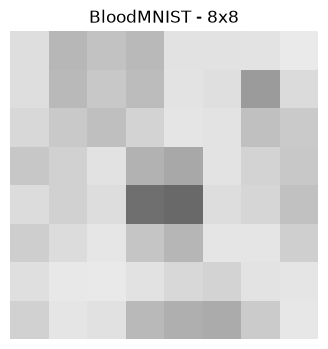

In [78]:
blood_8x8 = resize_image(
    original_blood_image,
    8
)

print("BloodMNIST 8x8:")
print(blood_8x8)

plt.figure(figsize=(4, 4))
plt.imshow(
    blood_8x8,
    cmap="gray",
    vmin=0,
    vmax=255
)
plt.title("BloodMNIST - 8x8")
plt.axis("off")
plt.show()

In [79]:
num_position_qubits_blood_8 = 6

color_blood_8 = QuantumRegister(
    1,
    "color"
)

position_blood_8 = QuantumRegister(
    num_position_qubits_blood_8,
    "position"
)

qc_blood_frqi_8x8 = QuantumCircuit(
    color_blood_8,
    position_blood_8
)

qc_blood_frqi_8x8.h(
    position_blood_8
)

qc_blood_frqi_8x8.barrier()

print(
    "Total qubits:",
    qc_blood_frqi_8x8.num_qubits
)

Total qubits: 7


In [80]:
#Encode
flat_blood_8 = blood_8x8.flatten()

for pixel_position, pixel_value in enumerate(
    flat_blood_8
):

    encode_frqi_pixel(
        qc_blood_frqi_8x8,
        position_blood_8,
        color_blood_8[0],
        pixel_position,
        int(pixel_value)
    )

qc_blood_frqi_8x8.barrier()

print("Pixels encoded:", len(flat_blood_8))

print(
    "Original depth:",
    qc_blood_frqi_8x8.depth()
)

print(
    "Gate counts:",
    qc_blood_frqi_8x8.count_ops()
)

Pixels encoded: 64
Original depth: 4875
Gate counts: OrderedDict({'p': 3840, 'cx': 3584, 'h': 518, 'x': 384, 'ry': 256, 'barrier': 2})


In [81]:
#Statevector

qc_blood_sv_8 = qc_blood_frqi_8x8.copy()
qc_blood_sv_8.save_statevector()

simulator_blood_8 = AerSimulator(
    method="statevector"
)

t_qc_blood_sv_8 = transpile(
    qc_blood_sv_8,
    simulator_blood_8
)

result_blood_sv_8 = simulator_blood_8.run(
    t_qc_blood_sv_8
).result()

statevector_blood_8 = np.asarray(
    result_blood_sv_8.get_statevector()
)

print(
    "Statevector length:",
    len(statevector_blood_8)
)

print(
    "Normalization:",
    np.sum(
        np.abs(statevector_blood_8) ** 2
    )
)

Statevector length: 128
Normalization: 1.0000000000000022


In [82]:
#reconstruct
reconstructed_blood_8 = []

num_pixels_blood_8 = 64

for p in range(num_pixels_blood_8):

    index_color_0 = 2 * p
    index_color_1 = 2 * p + 1

    amp0 = statevector_blood_8[
        index_color_0
    ]

    amp1 = statevector_blood_8[
        index_color_1
    ]

    amp0 *= np.sqrt(num_pixels_blood_8)
    amp1 *= np.sqrt(num_pixels_blood_8)

    theta = np.arctan2(
        np.abs(amp1),
        np.abs(amp0)
    )

    pixel_value = (
        theta / (np.pi / 2)
    ) * 255

    reconstructed_blood_8.append(
        int(round(pixel_value))
    )

reconstructed_blood_8 = np.array(
    reconstructed_blood_8
).reshape(8, 8)

print("Original:")
print(blood_8x8)

print("\nReconstructed:")
print(reconstructed_blood_8)

Original:
[[222 183 194 185 226 226 227 234]
 [222 185 200 188 227 223 155 219]
 [216 201 191 212 229 228 192 202]
 [199 209 226 178 168 228 212 200]
 [220 209 221 111 105 221 214 193]
 [206 220 230 197 182 229 229 207]
 [223 232 233 226 216 211 227 229]
 [209 229 225 185 175 171 203 231]]

Reconstructed:
[[222 183 194 185 226 226 227 234]
 [222 185 200 188 227 223 155 219]
 [216 201 191 212 229 228 192 202]
 [199 209 226 178 168 228 212 200]
 [220 209 221 111 105 221 214 193]
 [206 220 230 197 182 229 229 207]
 [223 232 233 226 216 211 227 229]
 [209 229 225 185 175 171 203 231]]


In [83]:
#Difference 
difference_blood_8 = (
    blood_8x8.astype(int)
    - reconstructed_blood_8.astype(int)
)

print("Difference:")
print(difference_blood_8)

print(
    "\nMaximum absolute error:",
    np.max(
        np.abs(difference_blood_8)
    )
)

Difference:
[[0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0]]

Maximum absolute error: 0


In [84]:
mse_blood_8 = np.mean(
    (
        blood_8x8.astype(float)
        - reconstructed_blood_8.astype(float)
    ) ** 2
)

if mse_blood_8 == 0:
    psnr_blood_8 = float("inf")
else:
    psnr_blood_8 = 10 * np.log10(
        (255 ** 2) / mse_blood_8
    )

print("MSE :", mse_blood_8)
print("PSNR:", psnr_blood_8)

MSE : 0.0
PSNR: inf


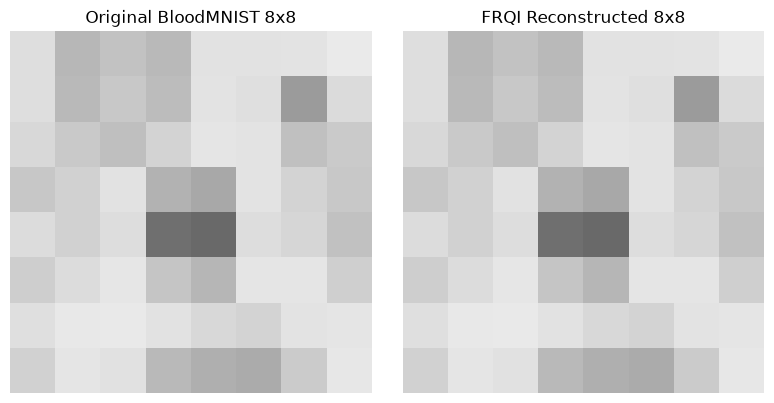

In [85]:
plt.figure(figsize=(8, 4))

plt.subplot(1, 2, 1)
plt.imshow(
    blood_8x8,
    cmap="gray",
    vmin=0,
    vmax=255
)
plt.title("Original BloodMNIST 8x8")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(
    reconstructed_blood_8,
    cmap="gray",
    vmin=0,
    vmax=255
)
plt.title("FRQI Reconstructed 8x8")
plt.axis("off")

plt.tight_layout()
plt.show()

In [86]:
#Transpilation
backend_blood_8 = AerSimulator()

transpiled_blood_8 = transpile(
    qc_blood_frqi_8x8,
    backend_blood_8
)

print("Original depth:",
      qc_blood_frqi_8x8.depth())

print("Transpiled depth:",
      transpiled_blood_8.depth())

print("\nOriginal gates:")
print(qc_blood_frqi_8x8.count_ops())

print("\nTranspiled gates:")
print(transpiled_blood_8.count_ops())

Original depth: 4875
Transpiled depth: 4106

Original gates:
OrderedDict({'p': 3840, 'cx': 3584, 'h': 518, 'x': 384, 'ry': 256, 'barrier': 2})

Transpiled gates:
OrderedDict({'cx': 2875, 'p': 2825, 'u3': 410, 'rzz': 272, 'u2': 172, 'cp': 143, 'u1': 32, 'rzx': 15, 'crx': 11, 'h': 6, 'rxx': 6, 'cry': 6, 'barrier': 2})


In [87]:
print("===== BLOODMNIST FRQI 8x8 SUMMARY =====")

print("Resolution       : 8x8")
print("Pixels           :", 64)
print("Position qubits  :", 6)
print("Color qubits     :", 1)
print("Total qubits     :", 7)

print(
    "Original depth   :",
    qc_blood_frqi_8x8.depth()
)

print(
    "Transpiled depth :",
    transpiled_blood_8.depth()
)

print(
    "Original CX      :",
    qc_blood_frqi_8x8.count_ops().get("cx", 0)
)

print(
    "Transpiled CX    :",
    transpiled_blood_8.count_ops().get("cx", 0)
)

print("MSE              :", mse_blood_8)
print("PSNR             :", psnr_blood_8)

print(
    "Maximum error    :",
    np.max(np.abs(difference_blood_8))
)

===== BLOODMNIST FRQI 8x8 SUMMARY =====
Resolution       : 8x8
Pixels           : 64
Position qubits  : 6
Color qubits     : 1
Total qubits     : 7
Original depth   : 4875
Transpiled depth : 4106
Original CX      : 3584
Transpiled CX    : 2875
MSE              : 0.0
PSNR             : inf
Maximum error    : 0


BloodMNIST 16x16:
[[233 223 179 175 188 176 172 199 228 222 215 215 230 229 236 235]
 [234 212 171 191 218 196 172 186 226 235 232 235 232 232 236 236]
 [231 212 173 191 221 205 174 184 227 230 230 224 172 165 227 231]
 [234 220 178 181 200 188 181 200 231 226 231 220 123 104 208 234]
 [229 229 202 178 178 174 189 218 232 233 231 225 159 159 221 216]
 [206 207 215 208 196 199 218 232 226 228 229 233 222 214 196 176]
 [186 186 197 228 233 223 230 211 200 222 233 232 227 202 188 199]
 [206 206 189 217 229 231 183 102  84 164 230 232 227 187 196 222]
 [222 221 197 213 233 229 125  73  77 105 223 232 227 187 192 204]
 [224 227 199 217 232 220 115  77  78 107 226 233 229 209 187 182]
 [216 210 201 224 234 230 197 148 111 189 234 231 232 225 207 180]
 [192 198 218 234 232 236 232 224 208 222 230 233 228 232 228 203]
 [212 220 233 236 231 238 226 233 231 231 227 231 229 229 232 224]
 [234 234 230 233 236 235 229 224 213 203 186 197 222 229 232 229]
 [214 225 232 232 232 227 201 179 172 173 16

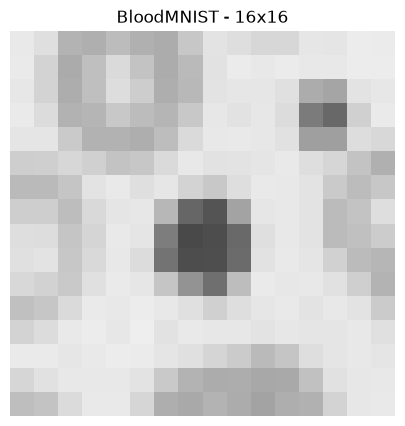

In [88]:
blood_16x16 = resize_image(
    original_blood_image,
    16
)

print("BloodMNIST 16x16:")
print(blood_16x16)

plt.figure(figsize=(5, 5))
plt.imshow(
    blood_16x16,
    cmap="gray",
    vmin=0,
    vmax=255
)
plt.title("BloodMNIST - 16x16")
plt.axis("off")
plt.show()

In [89]:
num_position_qubits_blood_16 = 8

color_blood_16 = QuantumRegister(
    1,
    "color"
)

position_blood_16 = QuantumRegister(
    num_position_qubits_blood_16,
    "position"
)

qc_blood_frqi_16x16 = QuantumCircuit(
    color_blood_16,
    position_blood_16
)

qc_blood_frqi_16x16.h(
    position_blood_16
)

qc_blood_frqi_16x16.barrier()

print(
    "Total qubits:",
    qc_blood_frqi_16x16.num_qubits
)

Total qubits: 9


In [90]:
flat_blood_16 = blood_16x16.flatten()

for pixel_position, pixel_value in enumerate(
    flat_blood_16
):

    encode_frqi_pixel(
        qc_blood_frqi_16x16,
        position_blood_16,
        color_blood_16[0],
        pixel_position,
        int(pixel_value)
    )

qc_blood_frqi_16x16.barrier()

print("Pixels encoded:", len(flat_blood_16))

print(
    "Original depth:",
    qc_blood_frqi_16x16.depth()
)

print(
    "Gate counts:",
    qc_blood_frqi_16x16.count_ops()
)

Pixels encoded: 256
Original depth: 50435
Gate counts: OrderedDict({'cx': 26624, 't': 16384, 'tdg': 14336, 'h': 12296, 'x': 2048, 'ry': 1024, 'barrier': 2})


In [ ]:
#Statevector
qc_blood_sv_16 = qc_blood_frqi_16x16.copy()
qc_blood_sv_16.save_statevector()

simulator_blood_16 = AerSimulator(
    method="statevector"
)

t_qc_blood_sv_16 = transpile(
    qc_blood_sv_16,
    simulator_blood_16
)

result_blood_sv_16 = simulator_blood_16.run(
    t_qc_blood_sv_16
).result()

statevector_blood_16 = np.asarray(
    result_blood_sv_16.get_statevector()
)

print(
    "Statevector length:",
    len(statevector_blood_16)
)

print(
    "Normalization:",
    np.sum(
        np.abs(statevector_blood_16) ** 2
    )
)

In [ ]:
#Reconstruct
reconstructed_blood_16 = []

num_pixels_blood_16 = 256

for p in range(num_pixels_blood_16):

    index_color_0 = 2 * p
    index_color_1 = 2 * p + 1

    amp0 = statevector_blood_16[
        index_color_0
    ]

    amp1 = statevector_blood_16[
        index_color_1
    ]

    amp0 *= np.sqrt(num_pixels_blood_16)
    amp1 *= np.sqrt(num_pixels_blood_16)

    theta = np.arctan2(
        np.abs(amp1),
        np.abs(amp0)
    )

    pixel_value = (
        theta / (np.pi / 2)
    ) * 255

    reconstructed_blood_16.append(
        int(round(pixel_value))
    )

reconstructed_blood_16 = np.array(
    reconstructed_blood_16
).reshape(16, 16)

print("Original:")
print(blood_16x16)

print("\nReconstructed:")
print(reconstructed_blood_16)

In [ ]:
#Difference
difference_blood_16 = (
    blood_16x16.astype(int)
    - reconstructed_blood_16.astype(int)
)

print("Difference:")
print(difference_blood_16)

print(
    "\nMaximum absolute error:",
    np.max(
        np.abs(difference_blood_16)
    )
)

In [ ]:
#MSE and PSNR
mse_blood_16 = np.mean(
    (
        blood_16x16.astype(float)
        - reconstructed_blood_16.astype(float)
    ) ** 2
)

if mse_blood_16 == 0:
    psnr_blood_16 = float("inf")
else:
    psnr_blood_16 = 10 * np.log10(
        (255 ** 2) / mse_blood_16
    )

print("MSE :", mse_blood_16)
print("PSNR:", psnr_blood_16)

In [ ]:
plt.figure(figsize=(8, 4))

plt.subplot(1, 2, 1)
plt.imshow(
    blood_16x16,
    cmap="gray",
    vmin=0,
    vmax=255
)
plt.title("Original BloodMNIST 16x16")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(
    reconstructed_blood_16,
    cmap="gray",
    vmin=0,
    vmax=255
)
plt.title("FRQI Reconstructed 16x16")
plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
#Transpilation
backend_blood_16 = AerSimulator()

transpiled_blood_16 = transpile(
    qc_blood_frqi_16x16,
    backend_blood_16
)

print(
    "Original depth:",
    qc_blood_frqi_16x16.depth()
)

print(
    "Transpiled depth:",
    transpiled_blood_16.depth()
)

print("\nOriginal gates:")
print(qc_blood_frqi_16x16.count_ops())

print("\nTranspiled gates:")
print(transpiled_blood_16.count_ops())

In [ ]:
print("===== BLOODMNIST FRQI 16x16 SUMMARY =====")

print("Resolution       : 16x16")
print("Pixels           :", 256)
print("Position qubits  :", 8)
print("Color qubits     :", 1)
print("Total qubits     :", 9)

print(
    "Original depth   :",
    qc_blood_frqi_16x16.depth()
)

print(
    "Transpiled depth :",
    transpiled_blood_16.depth()
)

print(
    "Original CX      :",
    qc_blood_frqi_16x16.count_ops().get("cx", 0)
)

print(
    "Transpiled CX    :",
    transpiled_blood_16.count_ops().get("cx", 0)
)

print("MSE              :", mse_blood_16)
print("PSNR             :", psnr_blood_16)

print(
    "Maximum error    :",
    np.max(np.abs(difference_blood_16))
)

In [ ]:
#Encode in NEQR
def encode_pixel_neqr(
    qc,
    position_qubits,
    intensity_qubits,
    pixel_position,
    pixel_value
):
    """
    Encode one 8-bit grayscale pixel using NEQR.
    """

    num_position_qubits = len(position_qubits)

    # Position of the pixel in binary
    position_binary = format(
        pixel_position,
        f"0{num_position_qubits}b"
    )

    # 8-bit grayscale value
    # Reverse for Qiskit's little-endian ordering
    intensity_binary = format(
        int(pixel_value),
        "08b"
    )[::-1]

    x_applied = []

    # Convert 0 position bits to 1-controls
    for q, bit in enumerate(position_binary):

        if bit == "0":

            qc.x(
                position_qubits[q]
            )

            x_applied.append(q)

    # Encode intensity bits
    for q, bit in enumerate(intensity_binary):

        if bit == "1":

            qc.mcx(
                list(position_qubits),
                intensity_qubits[q]
            )

    # Restore position qubits
    for q in x_applied:

        qc.x(
            position_qubits[q]
        )

In [ ]:
num_position_qubits_neqr_4 = 4
num_intensity_qubits_neqr_4 = 8

position_neqr_4 = QuantumRegister(
    num_position_qubits_neqr_4,
    "position"
)

intensity_neqr_4 = QuantumRegister(
    num_intensity_qubits_neqr_4,
    "intensity"
)

qc_neqr_4x4 = QuantumCircuit(
    intensity_neqr_4,
    position_neqr_4
)

# Put all 16 positions into superposition
qc_neqr_4x4.h(
    position_neqr_4
)

qc_neqr_4x4.barrier()

print("NEQR 4×4")
print("Position qubits :", num_position_qubits_neqr_4)
print("Intensity qubits:", num_intensity_qubits_neqr_4)
print("Total qubits    :", qc_neqr_4x4.num_qubits)

In [ ]:
#Encode 4x4 image using NEQR
flat_neqr_4 = image_4x4.flatten()

for pixel_position, pixel_value in enumerate(
    flat_neqr_4
):

    encode_pixel_neqr(
        qc_neqr_4x4,
        position_neqr_4,
        intensity_neqr_4,
        pixel_position,
        int(pixel_value)
    )

qc_neqr_4x4.barrier()

print("NEQR encoding completed.")
print("Pixels encoded:", len(flat_neqr_4))

print("\nOriginal depth:")
print(qc_neqr_4x4.depth())

print("\nGate counts:")
print(qc_neqr_4x4.count_ops())

In [ ]:
#NEQR 4x4 measurement
qc_neqr_measure_4 = qc_neqr_4x4.copy()

cr_neqr_4 = ClassicalRegister(
    qc_neqr_4x4.num_qubits,
    "cr"
)

qc_neqr_measure_4.add_register(
    cr_neqr_4
)

qc_neqr_measure_4.measure(
    range(qc_neqr_4x4.num_qubits),
    range(qc_neqr_4x4.num_qubits)
)

simulator_neqr_4 = AerSimulator()

transpiled_neqr_4 = transpile(
    qc_neqr_measure_4,
    simulator_neqr_4
)

result_neqr_4 = simulator_neqr_4.run(
    transpiled_neqr_4,
    shots=4096
).result()

counts_neqr_4 = result_neqr_4.get_counts()

print(
    "Number of measured states:",
    len(counts_neqr_4)
)

print("\nCounts:")
print(counts_neqr_4)

In [ ]:
plot_histogram(
    counts_neqr_4,
    figsize=(14, 6)
)

In [ ]:
def decode_neqr_counts(
    counts,
    image_size=4,
    num_intensity_bits=8
):
    """
    Decode NEQR measurement results
    back into a grayscale image.

    For a 4×4 image:
        4 position bits
        8 intensity bits
        total = 12 bits
    """

    num_position_bits = int(
        np.log2(image_size * image_size)
    )

    reconstructed = np.zeros(
        (image_size, image_size),
        dtype=np.uint8
    )

    # Store the most frequently observed
    # intensity for each pixel position
    position_candidates = {}

    for bitstring, count in counts.items():
        # Split measurement string
        position_bits_display = bitstring[
            :num_position_bits
        ]

        intensity_bits = bitstring[
            num_position_bits:
            num_position_bits + num_intensity_bits
        ]

        
        # Qiskit little-endian correction
        position_bits = (
            position_bits_display[::-1]
        )

        pixel_position = int(
            position_bits,
            2
        )

        pixel_value = int(
            intensity_bits,
            2
        )

        # Store candidate
        if pixel_position not in position_candidates:

            position_candidates[pixel_position] = []

        position_candidates[pixel_position].append(
            (pixel_value, count)
        )

    # Select the most frequently observed
    # intensity for each position

    for pixel_position, candidates in position_candidates.items():

        best_value, best_count = max(
            candidates,
            key=lambda x: x[1]
        )

        row = pixel_position // image_size
        col = pixel_position % image_size

        reconstructed[row, col] = best_value

    return reconstructed

In [ ]:
reconstructed_neqr_4x4 = decode_neqr_counts(
    counts_neqr_4,
    image_size=4
)

print("Original 4×4 image:")
print(image_4x4)

print("\nReconstructed NEQR image:")
print(reconstructed_neqr_4x4)

In [ ]:
#Pixel-wise reconstruction error
neqr_difference = np.abs(
    image_4x4.astype(int)
    -
    reconstructed_neqr_4x4.astype(int)
)

print("Absolute difference:")
print(neqr_difference)

print(
    "\nMaximum pixel error:",
    neqr_difference.max()
)

In [ ]:
#original vs NEQR reconstruction
fig, axes = plt.subplots(
    1,
    3,
    figsize=(12, 4)
)

axes[0].imshow(
    image_4x4,
    cmap="gray",
    interpolation="nearest"
)

axes[0].set_title(
    "Original 4×4"
)

axes[0].axis("off")


axes[1].imshow(
    reconstructed_neqr_4x4,
    cmap="gray",
    interpolation="nearest"
)

axes[1].set_title(
    "NEQR Reconstruction"
)

axes[1].axis("off")


axes[2].imshow(
    neqr_difference,
    cmap="gray",
    interpolation="nearest"
)

axes[2].set_title(
    "Absolute Error"
)

axes[2].axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# ==========================================
# NEQR 4×4 Reconstruction Metrics
# ==========================================

from skimage.metrics import (
    mean_squared_error,
    peak_signal_noise_ratio,
    structural_similarity
)

# Convert to floating point for safe calculations
original = image_4x4.astype(np.float64)
reconstructed = reconstructed_neqr_4x4.astype(np.float64)

# ------------------------------------------
# MSE
# ------------------------------------------

mse_neqr_4 = mean_squared_error(
    original,
    reconstructed
)

# ------------------------------------------
# MAE
# ------------------------------------------

mae_neqr_4 = np.mean(
    np.abs(
        original - reconstructed
    )
)

# ------------------------------------------
# PSNR
# ------------------------------------------

if mse_neqr_4 == 0:

    psnr_neqr_4 = np.inf

else:

    psnr_neqr_4 = peak_signal_noise_ratio(
        original,
        reconstructed,
        data_range=255
    )

# SSIM
ssim_neqr_4 = structural_similarity(
    original,
    reconstructed,
    data_range=255,
    win_size=3
)

print("NEQR 4×4 Reconstruction Metrics")
print("=" * 45)

print("MSE  :", mse_neqr_4)
print("MAE  :", mae_neqr_4)
print("PSNR :", psnr_neqr_4)
print("SSIM :", ssim_neqr_4)

In [ ]:
original_neqr_4_ops = qc_neqr_4x4.count_ops()
transpiled_neqr_4_ops = transpiled_neqr_4.count_ops()

print("NEQR 4×4 Resource Metrics")
print("=" * 50)

print("Total qubits       :", qc_neqr_4x4.num_qubits)
print("Original depth     :", qc_neqr_4x4.depth())
print("Transpiled depth   :", transpiled_neqr_4.depth())

print("\nOriginal gate counts:")
print(original_neqr_4_ops)

print("\nTranspiled gate counts:")
print(transpiled_neqr_4_ops)

print("\nTotal original gates:",
      sum(original_neqr_4_ops.values()))

print("Total transpiled gates:",
      sum(transpiled_neqr_4_ops.values()))

print("\nOriginal CX gates:",
      original_neqr_4_ops.get("cx", 0))

print("Transpiled CX gates:",
      transpiled_neqr_4_ops.get("cx", 0))

In [ ]:
#NEQR 8x8
num_position_qubits_neqr_8 = 6
num_intensity_qubits_neqr_8 = 8

position_neqr_8 = QuantumRegister(
    num_position_qubits_neqr_8,
    "position"
)

intensity_neqr_8 = QuantumRegister(
    num_intensity_qubits_neqr_8,
    "intensity"
)

qc_neqr_8x8 = QuantumCircuit(
    intensity_neqr_8,
    position_neqr_8
)

# Create equal superposition of all 64 pixel positions
qc_neqr_8x8.h(position_neqr_8)

qc_neqr_8x8.barrier()

print("NEQR 8×8")
print("=" * 40)
print("Position qubits :", num_position_qubits_neqr_8)
print("Intensity qubits:", num_intensity_qubits_neqr_8)
print("Total qubits    :", qc_neqr_8x8.num_qubits)

In [ ]:
#Encode 8x8 image using NEQR
flat_neqr_8 = image_8x8.flatten()

for pixel_position, pixel_value in enumerate(
    flat_neqr_8
):

    encode_pixel_neqr(
        qc_neqr_8x8,
        position_neqr_8,
        intensity_neqr_8,
        pixel_position,
        int(pixel_value)
    )

qc_neqr_8x8.barrier()

print("NEQR 8×8 encoding completed.")
print("Pixels encoded:", len(flat_neqr_8))

print("\nOriginal depth:")
print(qc_neqr_8x8.depth())

print("\nGate counts:")
print(qc_neqr_8x8.count_ops())

In [ ]:
#8x8 NEQR Measurement
qc_neqr_measure_8 = qc_neqr_8x8.copy()

cr_neqr_8 = ClassicalRegister(
    qc_neqr_8x8.num_qubits,
    "cr"
)

qc_neqr_measure_8.add_register(
    cr_neqr_8
)

qc_neqr_measure_8.measure(
    range(qc_neqr_8x8.num_qubits),
    range(qc_neqr_8x8.num_qubits)
)

In [ ]:
simulator_neqr_8 = AerSimulator()

transpiled_neqr_8 = transpile(
    qc_neqr_measure_8,
    simulator_neqr_8,
    optimization_level=1
)

result_neqr_8 = simulator_neqr_8.run(
    transpiled_neqr_8,
    shots=4096
).result()

counts_neqr_8 = result_neqr_8.get_counts()

print("Number of measured states:",
      len(counts_neqr_8))

print("\nTotal shots:",
      sum(counts_neqr_8.values()))

In [ ]:
#Decode 
reconstructed_neqr_8x8 = decode_neqr_counts(
    counts_neqr_8,
    image_size=8
)

print("Original 8×8 image:")
print(image_8x8)

print("\nReconstructed NEQR 8×8:")
print(reconstructed_neqr_8x8)

In [ ]:
#Check reconstruct error
neqr_difference_8 = np.abs(
    image_8x8.astype(int)
    -
    reconstructed_neqr_8x8.astype(int)
)

print(
    "\nMaximum pixel error:",
    neqr_difference_8.max()
)

In [ ]:
fig, axes = plt.subplots(
    1,
    3,
    figsize=(12, 4)
)

axes[0].imshow(
    image_8x8,
    cmap="gray",
    interpolation="nearest"
)

axes[0].set_title("Original 8×8")
axes[0].axis("off")


axes[1].imshow(
    reconstructed_neqr_8x8,
    cmap="gray",
    interpolation="nearest"
)

axes[1].set_title("NEQR Reconstruction")
axes[1].axis("off")


axes[2].imshow(
    neqr_difference_8,
    cmap="gray",
    interpolation="nearest"
)

axes[2].set_title("Absolute Error")
axes[2].axis("off")

plt.tight_layout()
plt.show()

In [ ]:
original_8 = image_8x8.astype(np.float64)
reconstructed_8 = reconstructed_neqr_8x8.astype(np.float64)

mse_neqr_8 = mean_squared_error(
    original_8,
    reconstructed_8
)

mae_neqr_8 = np.mean(
    np.abs(
        original_8 - reconstructed_8
    )
)

if mse_neqr_8 == 0:

    psnr_neqr_8 = np.inf

else:

    psnr_neqr_8 = peak_signal_noise_ratio(
        original_8,
        reconstructed_8,
        data_range=255
    )

ssim_neqr_8 = structural_similarity(
    original_8,
    reconstructed_8,
    data_range=255
)

print("NEQR 8×8 Reconstruction Metrics")
print("=" * 45)

print("MSE  :", mse_neqr_8)
print("MAE  :", mae_neqr_8)
print("PSNR :", psnr_neqr_8)
print("SSIM :", ssim_neqr_8)

In [ ]:
original_neqr_8_ops = qc_neqr_8x8.count_ops()
transpiled_neqr_8_ops = transpiled_neqr_8.count_ops()

print("NEQR 8×8 Resource Metrics")
print("=" * 50)

print("Total qubits:",
      qc_neqr_8x8.num_qubits)

print("Original depth:",
      qc_neqr_8x8.depth())

print("Transpiled depth:",
      transpiled_neqr_8.depth())

print("\nOriginal gate counts:")
print(original_neqr_8_ops)

print("\nTranspiled gate counts:")
print(transpiled_neqr_8_ops)

print("\nTotal original gates:",
      sum(original_neqr_8_ops.values()))

print("Total transpiled gates:",
      sum(transpiled_neqr_8_ops.values()))

print("\nOriginal CX gates:",
      original_neqr_8_ops.get("cx", 0))

print("Transpiled CX gates:",
      transpiled_neqr_8_ops.get("cx", 0))

In [ ]:
num_position_qubits_neqr_16 = 8
num_intensity_qubits_neqr_16 = 8

position_neqr_16 = QuantumRegister(8, "position")
intensity_neqr_16 = QuantumRegister(8, "intensity")

qc_neqr_16x16 = QuantumCircuit(
    intensity_neqr_16,
    position_neqr_16
)

qc_neqr_16x16.h(position_neqr_16)
qc_neqr_16x16.barrier()

print("NEQR 16×16 circuit created")
print("Total qubits:", qc_neqr_16x16.num_qubits)

In [ ]:
#Encode 16x16 
flat_neqr_16 = image_16x16.flatten()

for pixel_position, pixel_value in enumerate(flat_neqr_16):
    encode_pixel_neqr(
        qc_neqr_16x16,
        position_neqr_16,
        intensity_neqr_16,
        pixel_position,
        int(pixel_value)
    )

qc_neqr_16x16.barrier()

print("NEQR 16×16 encoding completed")
print("Pixels encoded:", len(flat_neqr_16))
print("Total qubits:", qc_neqr_16x16.num_qubits)

In [ ]:
qc_neqr_measure_16 = qc_neqr_16x16.copy()

cr_neqr_16 = ClassicalRegister(
    qc_neqr_16x16.num_qubits,
    "cr"
)

qc_neqr_measure_16.add_register(cr_neqr_16)

qc_neqr_measure_16.measure(
    range(qc_neqr_16x16.num_qubits),
    range(qc_neqr_16x16.num_qubits)
)

In [ ]:
simulator_neqr_16 = AerSimulator()

transpiled_neqr_16 = transpile(
    qc_neqr_measure_16,
    simulator_neqr_16,
    optimization_level=1
)

result_neqr_16 = simulator_neqr_16.run(
    transpiled_neqr_16,
    shots=4096
).result()

counts_neqr_16 = result_neqr_16.get_counts()


print("\nMeasurement completed")
print("Total shots:", sum(counts_neqr_16.values()))
print("Unique measured states:", len(counts_neqr_16))

In [ ]:
#Reconstruct
reconstructed_neqr_16x16 = decode_neqr_counts(
    counts_neqr_16,
    image_size=16
)

neqr_difference_16 = np.abs(
    image_16x16.astype(int) -
    reconstructed_neqr_16x16.astype(int)
)

print("\nMaximum pixel error:", neqr_difference_16.max())


In [ ]:
original_16 = image_16x16.astype(np.float64)
reconstructed_16 = reconstructed_neqr_16x16.astype(np.float64)

mse_neqr_16 = mean_squared_error(
    original_16,
    reconstructed_16
)

mae_neqr_16 = np.mean(
    np.abs(original_16 - reconstructed_16)
)

if mse_neqr_16 == 0:

    psnr_neqr_16 = np.inf

else:

    psnr_neqr_16 = peak_signal_noise_ratio(
        original_16,
        reconstructed_16,
        data_range=255
    )

ssim_neqr_16 = structural_similarity(
    original_16,
    reconstructed_16,
    data_range=255
)

print("\nNEQR 16×16 Reconstruction Metrics")
print("=" * 45)
print("MSE  :", mse_neqr_16)
print("MAE  :", mae_neqr_16)
print("PSNR :", psnr_neqr_16)
print("SSIM :", ssim_neqr_16)

In [ ]:
original_neqr_16_ops = qc_neqr_16x16.count_ops()
transpiled_neqr_16_ops = transpiled_neqr_16.count_ops()

print("\nNEQR 16×16 Resource Metrics")
print("=" * 50)

print("Total qubits       :", qc_neqr_16x16.num_qubits)
print("Original depth     :", qc_neqr_16x16.depth())
print("Transpiled depth   :", transpiled_neqr_16.depth())

print("\nOriginal gate counts:")
print(original_neqr_16_ops)

print("\nTranspiled gate counts:")
print(transpiled_neqr_16_ops)

print("\nTotal original gates:",
      sum(original_neqr_16_ops.values()))

print("Total transpiled gates:",
      sum(transpiled_neqr_16_ops.values()))

print("\nOriginal CX gates:",
      original_neqr_16_ops.get("cx", 0))

print("Transpiled CX gates:",
      transpiled_neqr_16_ops.get("cx", 0))


In [ ]:
neqr_16_result = {
    "Representation": "NEQR",
    "Resolution": "16x16",
    "Qubits": qc_neqr_16x16.num_qubits,
    "Original Depth": qc_neqr_16x16.depth(),
    "Transpiled Depth": transpiled_neqr_16.depth(),
    "Original Gates": sum(original_neqr_16_ops.values()),
    "Transpiled Gates": sum(transpiled_neqr_16_ops.values()),
    "Original CX": original_neqr_16_ops.get("cx", 0),
    "Transpiled CX": transpiled_neqr_16_ops.get("cx", 0),
    "MSE": mse_neqr_16,
    "MAE": mae_neqr_16,
    "PSNR": psnr_neqr_16,
    "SSIM": ssim_neqr_16
}

print("\nFinal NEQR 16×16 result:")
print(neqr_16_result)

In [ ]:
#Count actual gate categories from a circuit
def circuit_gate_summary(qc):

    single_qubit = 0
    two_qubit = 0
    multi_qubit = 0

    ignored = {
        "measure",
        "barrier",
        "reset",
        "delay"
    }

    for instruction in qc.data:

        operation = instruction.operation
        name = operation.name

        if name in ignored:
            continue

        num_qubits = operation.num_qubits

        if num_qubits == 1:
            single_qubit += 1

        elif num_qubits == 2:
            two_qubit += 1

        elif num_qubits > 2:
            multi_qubit += 1

    return single_qubit, two_qubit, multi_qubit


In [ ]:
#Calculate reconstruction metrics
def reconstruction_metrics(original, reconstructed):

    original = original.astype(np.float64)
    reconstructed = reconstructed.astype(np.float64)

    mse = np.mean(
        (original - reconstructed) ** 2
    )

    mae = np.mean(
        np.abs(original - reconstructed)
    )

    if mse == 0:
        psnr = np.inf
    else:
        psnr = 10 * np.log10(
            (255 ** 2) / mse
        )

    # SSIM window size
    image_size = original.shape[0]

    if image_size <= 7:
        from skimage.metrics import structural_similarity

        ssim = structural_similarity(
            original,
            reconstructed,
            data_range=255,
            win_size=3
        )
    else:
        from skimage.metrics import structural_similarity

        ssim = structural_similarity(
            original,
            reconstructed,
            data_range=255
        )

    max_error = np.max(
        np.abs(original - reconstructed)
    )

    return mse, mae, psnr, ssim, max_error

In [ ]:
#Create one result row
def create_comparison_row(
    representation,
    resolution,
    original_circuit,
    transpiled_circuit,
    original_image,
    reconstructed_image,
    shots=4096
):

    # Resource metrics
    original_ops = original_circuit.count_ops()
    transpiled_ops = transpiled_circuit.count_ops()

    original_single, original_two, original_multi = (
        circuit_gate_summary(original_circuit)
    )

    transpiled_single, transpiled_two, transpiled_multi = (
        circuit_gate_summary(transpiled_circuit)
    )

    # Reconstruction metrics
    mse, mae, psnr, ssim, max_error = (
        reconstruction_metrics(
            original_image,
            reconstructed_image
        )
    )

    return {
        "Representation": representation,
        "Resolution": resolution,

        "Qubits": original_circuit.num_qubits,

        "Original Depth": original_circuit.depth(),
        "Transpiled Depth": transpiled_circuit.depth(),

        "Original Gates": sum(original_ops.values()),
        "Transpiled Gates": sum(transpiled_ops.values()),

        "Original 1-Q Gates": original_single,
        "Transpiled 1-Q Gates": transpiled_single,

        "Original 2-Q Gates": original_two,
        "Transpiled 2-Q Gates": transpiled_two,

        "Original Multi-Q Gates": original_multi,
        "Transpiled Multi-Q Gates": transpiled_multi,

        "MSE": mse,
        "MAE": mae,
        "PSNR": psnr,
        "SSIM": ssim,
        "Maximum Error": max_error,

        "Shots": shots
    }

In [ ]:
#FRQI results
frqi_4 = create_comparison_row(
    "FRQI",
    "4x4",
    qc_frqi_4x4,
    transpiled_frqi_4x4,
    image_4x4,
    reconstructed_4x4
)

frqi_8 = create_comparison_row(
    "FRQI",
    "8x8",
    qc_frqi_8x8,
    transpiled_8,
    image_8x8,
    reconstructed_8
)

frqi_16 = create_comparison_row(
    "FRQI",
    "16x16",
    qc_frqi_16x16,
    transpiled_16,
    image_16x16,
    reconstructed_16
)



In [ ]:
#NEQR results
neqr_4 = create_comparison_row(
    "NEQR",
    "4x4",
    qc_neqr_4x4,
    transpiled_neqr_4,
    image_4x4,
    reconstructed_neqr_4x4
)

neqr_8 = create_comparison_row(
    "NEQR",
    "8x8",
    qc_neqr_8x8,
    transpiled_neqr_8,
    image_8x8,
    reconstructed_neqr_8x8
)

neqr_16 = create_comparison_row(
    "NEQR",
    "16x16",
    qc_neqr_16x16,
    transpiled_neqr_16,
    image_16x16,
    reconstructed_neqr_16x16
)

In [ ]:
import numpy as np
import pandas as pd
#Combine
comparison_df = pd.DataFrame([
    frqi_4,
    neqr_4,
    frqi_8,
    neqr_8,
    frqi_16,
    neqr_16
])

In [ ]:
print("=" * 100)
print("FRQI vs NEQR — IDEAL COMPARISON")
print("Dataset: PneumoniaMNIST")
print("=" * 100)

display(comparison_df)